# Лабораторна робота 7
## Логістична регресія та порятунок принцеси

**Виконав:** Халявка Даниїл, курс 4, група 9.

**Мета:** дослідити дані Cure the Princess, навчити логістичну регресію, підібрати її параметри та порівняти результат із SVM і деревом рішень.

Потрібно передбачити Cured: 1 означає, що принцесу вилікувано, 0 означає, що її не вилікувано. Ознаками є кількості 13 магічних інгредієнтів. Це навчальний набір даних.

Ноутбук виконується послідовно зверху вниз. Дані читаються з data.csv поруч із файлом або автоматично завантажуються за посиланням викладача.

[Початковий шаблон](https://colab.research.google.com/drive/1Bn9rFAlfp73PleMWQiJ0CafHW-fyfm0L) · [Дані викладача](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view)

Джерело набору даних: [Cure the Princess на Kaggle](https://www.kaggle.com/datasets/unmoved/cure-the-princess).

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

Бібліотеки імпортовано. pandas і NumPy потрібні для даних, matplotlib та seaborn для графіків, scikit-learn для навчання й перевірки моделей.

### 2. Завантаження даних

Використано один спосіб: pandas читає CSV. Якщо локального файла немає, завантажується той самий data.csv за посиланням викладача. Додатково завантажувати файл вручну в Colab не потрібно.

In [2]:
data_path = Path("data.csv")
data_url = "https://drive.google.com/uc?export=download&id=1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH"
df = pd.read_csv(data_path if data_path.exists() else data_url)
df.head()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


Використано data.csv із завдання. Альтернативний спосіб через KaggleHub не запускався, щоб не завантажувати дані двічі.

### Опис даних

Цільова змінна **`Cured`**: `1` - принцесу вилікувано; `0` - не вилікувано. Інші стовпці - характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) - перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) - ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) - кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) - сльози міфічної істоти - русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) - магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) - палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) - зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) - лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) - волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) - чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) - ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) - луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) - зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) - цільова змінна: 1 - принцесу вилікувано, 0 - не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [3]:
display(df.head())
df.info()
print("Розмір датасету:", df.shape)

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB
Розмір датасету: (2338, 14)


In [4]:
display(df.isnull().sum().rename("Пропуски").to_frame())
print("Кількість дублікатів:", df.duplicated().sum())

,Пропуски
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


Кількість дублікатів: 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Phoenix Feather,2338.0,15.365697,8.669969,1.0,8.500,14.7,21.300,42.1
Unicorn Horn,2338.0,10.946749,7.225162,1.0,5.300,9.5,15.575,34.1
Dragon's Blood,2338.0,16.115654,8.372518,1.0,9.600,15.8,22.000,40.8
Mermaid Tears,2338.0,13.627973,7.545244,1.0,7.600,13.1,19.000,35.8
Fairy Dust,2338.0,15.069504,8.349340,1.0,8.625,14.5,20.700,40.4
Goblin Toes,2338.0,14.157271,7.831476,1.0,7.900,13.5,19.500,37.8
Witch's Brew,2338.0,12.328914,7.709753,1.0,6.325,11.2,16.900,37.3
Griffin Claw,2338.0,14.911206,8.132678,1.0,8.400,14.4,20.500,39.4
Troll Hair,2338.0,16.871685,9.579027,1.0,8.900,16.3,24.000,44.8
Kraken Ink,2338.0,14.890590,8.014197,1.0,8.800,14.4,20.400,39.5


**Висновок за первинним оглядом.** Датасет містить 2338 рядків і 14 стовпців: 13 числових ознак та Cured. Пропусків і повних дублікатів немає. Ознаки мають різні масштаби, тому перед логістичною регресією та SVM їх потрібно стандартизувати. Заповнювати пропуски чи вилучати дублікати не довелося.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [6]:
X = df.drop(columns="Cured")
y = df["Cured"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (1870, 13)
Тестова вибірка: (468, 13)


**Висновок про поділ.** Отримано 1870 навчальних і 468 тестових спостережень. Вони не перетинаються. Поділ 80% / 20% виконано з random_state = 42 до аналізу викидів і кореляцій.

### 5. Баланс класів на навчальній вибірці

In [7]:
class_counts = y_train.value_counts().sort_index()
display(pd.DataFrame({
    "Кількість": class_counts,
    "Частка, %": (class_counts / len(y_train) * 100).round(2)
}))

,Кількість,"Частка, %"
Cured,,
0,946,50.59
1,924,49.41


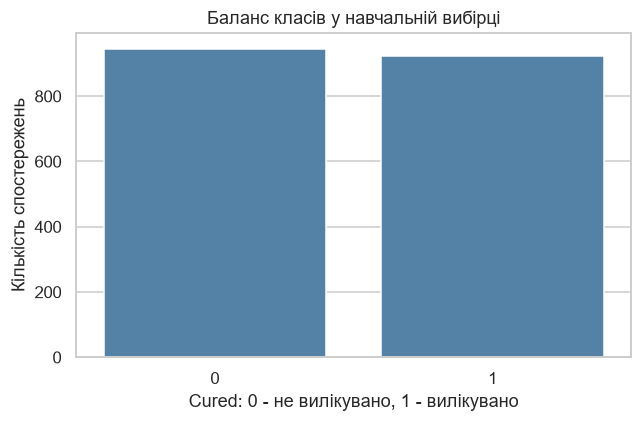

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train, color="steelblue")
plt.title("Баланс класів у навчальній вибірці")
plt.xlabel("Cured: 0 - не вилікувано, 1 - вилікувано")
plt.ylabel("Кількість спостережень")
plt.tight_layout()
plt.show()

**Висновок про баланс класів.** У навчальній вибірці 946 прикладів класу 0 та 924 приклади класу 1, тобто приблизно 50,59% і 49,41%. Класи майже збалансовані. Значного перекосу немає, але разом з Accuracy варто перевіряти precision, recall та F1, щоб бачити якість для обох класів.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

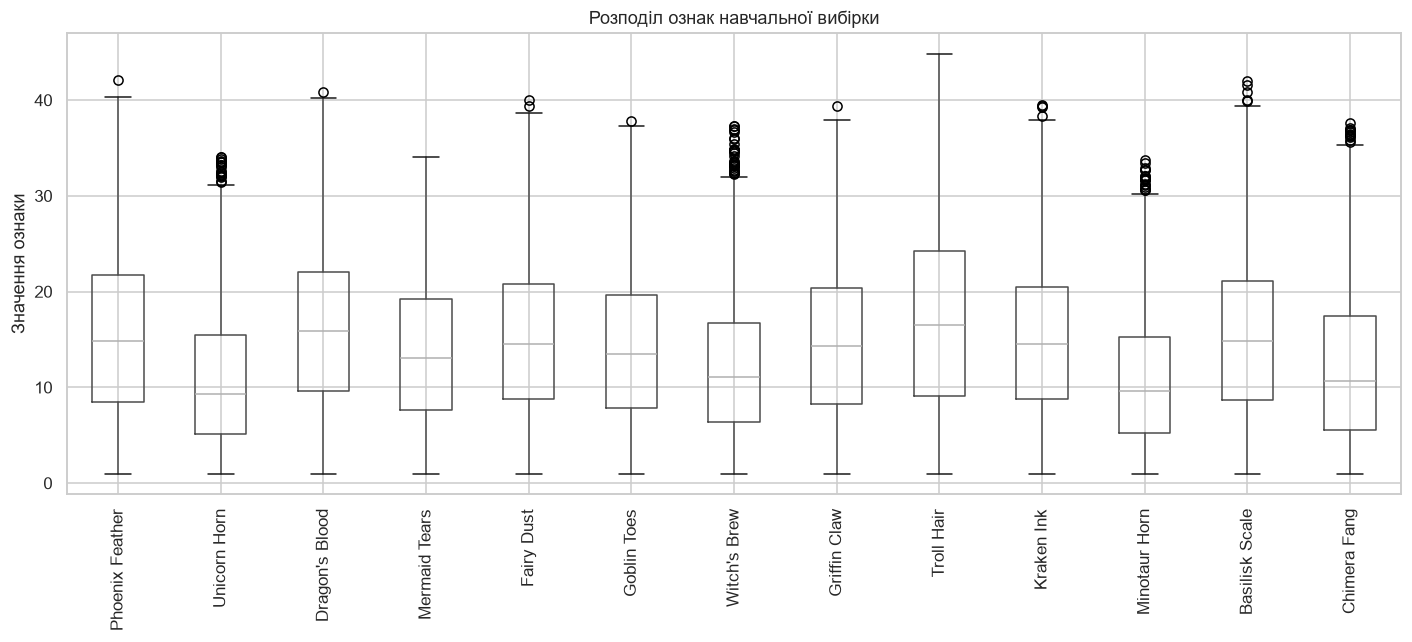

In [9]:
X_train.boxplot(figsize=(13, 6), rot=90)
plt.title("Розподіл ознак навчальної вибірки")
plt.ylabel("Значення ознаки")
plt.tight_layout()
plt.show()

In [10]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
outlier_counts = (
    (X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)
).sum().sort_values(ascending=False)
display(outlier_counts.rename("Потенційні викиди").to_frame())

,Потенційні викиди
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


**Висновок про викиди.** Найбільше потенційних викидів за правилом 1,5 IQR знайдено у Witch's Brew: 33, Unicorn Horn: 20 та Minotaur Horn: 18. Таке значення не обов’язково є помилкою. Воно може бути рідкісним коректним прикладом, тому в основному експерименті всі навчальні рядки залишено. Тестову вибірку не очищено за цим правилом.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

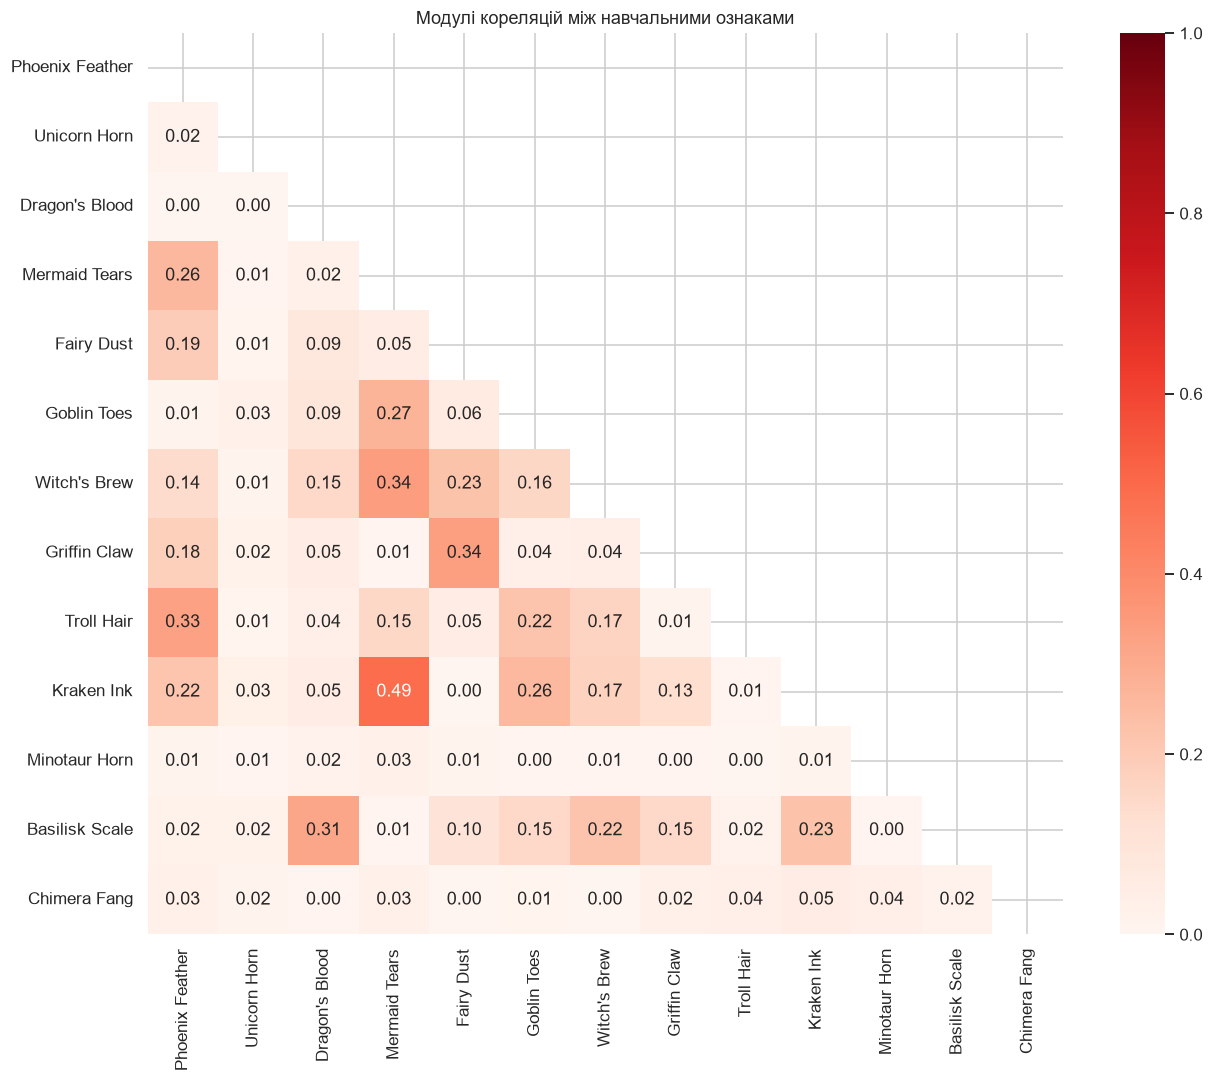

In [11]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(mtx, mask=mask, annot=True, fmt=".2f",
            cmap="Reds", vmin=0, vmax=1)
plt.title("Модулі кореляцій між навчальними ознаками")
plt.tight_layout()
plt.show()

In [12]:
target_corr = pd.concat([X_train, y_train], axis=1).corr()["Cured"].drop("Cured")
target_corr = target_corr.sort_values(key=lambda values: values.abs(), ascending=False)
display(target_corr.rename("Кореляція з Cured").to_frame())
pairs = mtx.where(np.tril(np.ones_like(mtx, dtype=bool), k=-1)).stack()
display(pairs.sort_values(ascending=False).head(3).rename("Модуль кореляції").to_frame())

,Кореляція з Cured
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


,,Модуль кореляції
Kraken Ink,Mermaid Tears,0.490744
Witch's Brew,Mermaid Tears,0.343493
Griffin Claw,Fairy Dust,0.339391


**Висновок про кореляції.** Найбільший модуль кореляції між ознаками мають Kraken Ink і Mermaid Tears: 0,4907. Наступні пари: Witch's Brew і Mermaid Tears: 0,3435; Griffin Claw і Fairy Dust: 0,3394. Зв’язки помірні, майже однакових за лінійною залежністю ознак не видно. Найсильніше з Cured пов’язані Troll Hair: 0,4888 та Witch's Brew: 0,2470. Кореляція показує лінійний зв’язок і сама по собі не доводить причинного впливу. Усі ці розрахунки виконано лише на навчальній вибірці.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` - `fit_transform()`, для `X_test` - тільки `transform()`.

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Після стандартизації навчальної вибірки:")
print("Найбільший модуль середнього:", np.abs(X_train_scaled.mean(axis=0)).max())
print("Стандартні відхилення:", X_train_scaled.std(axis=0).round(3))

Після стандартизації навчальної вибірки:
Найбільший модуль середнього: 2.298814733341501e-16
Стандартні відхилення: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Параметри StandardScaler обчислено лише за X_train. До X_test застосовано вже навчене перетворення.

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [14]:
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
base_accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(base_accuracy, 4))
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

Accuracy: 0.8932
              precision    recall  f1-score   support

           0     0.8884    0.8961    0.8922       231
           1     0.8979    0.8903    0.8941       237

    accuracy                         0.8932       468
   macro avg     0.8931    0.8932    0.8932       468
weighted avg     0.8932    0.8932    0.8932       468



Базова модель навчалася лише на навчальній вибірці. Нижче розглянуто її помилки та приклади прогнозів.

### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

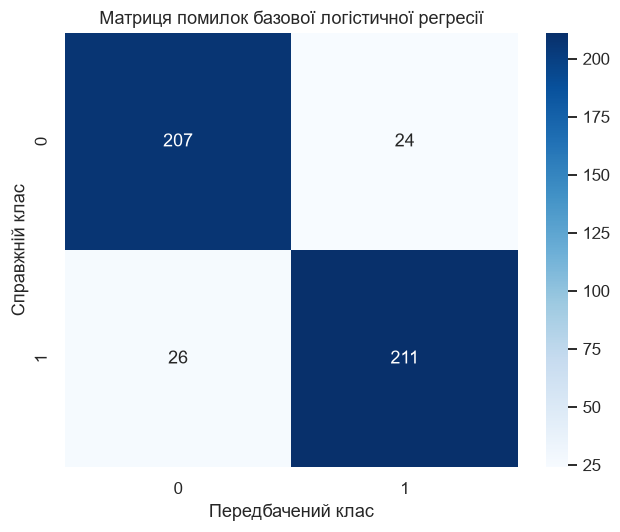

In [15]:
conf = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(conf, annot=True, fmt="d", cmap="Blues",
            xticklabels=[0, 1], yticklabels=[0, 1])
plt.title("Матриця помилок базової логістичної регресії")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.tight_layout()
plt.show()

In [16]:
predictions = pd.DataFrame({
    "Справжній клас": y_test,
    "Передбачений клас": y_pred
})
predictions.sample(10, random_state=42)

,Справжній клас,Передбачений клас
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості базової моделі.** Accuracy логістичної регресії дорівнює 0,8932, тобто правильно класифіковано 418 із 468 тестових прикладів. Матриця помилок містить 24 випадки, коли модель помилково передбачила вилікування, і 26 випадків, коли вона не розпізнала вилікування. Другий тип трапляється трохи частіше. Однієї Accuracy недостатньо: вона не показує, як помилки розподілені між класами.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

Для пошуку застосовано Pipeline зі StandardScaler і LogisticRegression. Це дозволяє заново навчати стандартизацію тільки на навчальній частині кожної складки CV. У пошук передаються початкові X_train, а Pipeline сам виконує перетворення. Позначення model__C означає параметр C моделі всередині Pipeline.

In [17]:
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["lbfgs", "liblinear"],
    "model__max_iter": [200, 1000]
}
param_dist = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "model__solver": ["lbfgs", "liblinear"],
    "model__max_iter": [200, 500, 1000]
}
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(random_state=42))
])

In [18]:
grid = GridSearchCV(pipeline, param_grid, cv=3,
                    scoring="accuracy", n_jobs=1)
grid.fit(X_train, y_train)
print("Найкращі параметри GridSearchCV:", grid.best_params_)
print("Середня Accuracy на CV:", round(grid.best_score_, 4))

Найкращі параметри GridSearchCV: {'model__C': 10, 'model__max_iter': 200, 'model__solver': 'lbfgs'}
Середня Accuracy на CV: 0.8674


In [19]:
random_search = RandomizedSearchCV(
    pipeline, param_dist, n_iter=12, cv=3, scoring="accuracy",
    random_state=42, n_jobs=1
)
random_search.fit(X_train, y_train)
print("Найкращі параметри RandomizedSearchCV:", random_search.best_params_)
print("Середня Accuracy на CV:", round(random_search.best_score_, 4))

Найкращі параметри RandomizedSearchCV: {'model__solver': 'liblinear', 'model__max_iter': 200, 'model__C': 10}
Середня Accuracy на CV: 0.8674


In [20]:
best_search = grid if grid.best_score_ >= random_search.best_score_ else random_search
best_model = best_search.best_estimator_
tuned_pred = best_model.predict(X_test)
tuned_accuracy = accuracy_score(y_test, tuned_pred)
print("Обраний пошук:", type(best_search).__name__)
print("Accuracy після підбору:", round(tuned_accuracy, 4))
print(classification_report(y_test, tuned_pred, digits=4, zero_division=0))

Обраний пошук: GridSearchCV
Accuracy після підбору: 0.8932
              precision    recall  f1-score   support

           0     0.8884    0.8961    0.8922       231
           1     0.8979    0.8903    0.8941       237

    accuracy                         0.8932       468
   macro avg     0.8931    0.8932    0.8932       468
weighted avg     0.8932    0.8932    0.8932       468



**Висновок про підбір параметрів.** GridSearchCV обрав C = 10, solver = lbfgs, max_iter = 200. RandomizedSearchCV обрав C = 10, solver = liblinear, max_iter = 200. Обидва пошуки отримали однакову середню Accuracy на трьох складках: 0,8674. Через однаковий результат обрано модель GridSearchCV. Її тестова Accuracy залишилася 0,8932, тому підбір у цьому експерименті не покращив результат базової моделі. Параметри обиралися за CV, а не за тестовою вибіркою.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [21]:
svm = SVC()
tree = DecisionTreeClassifier(random_state=42)
svm.fit(X_train_scaled, y_train)
tree.fit(X_train_scaled, y_train)
svm_pred = svm.predict(X_test_scaled)
tree_pred = tree.predict(X_test_scaled)
results = pd.DataFrame([
    {"Модель": "Логістична регресія", "Accuracy": accuracy_score(y_test, tuned_pred),
     "F1-score": f1_score(y_test, tuned_pred)},
    {"Модель": "SVM", "Accuracy": accuracy_score(y_test, svm_pred),
     "F1-score": f1_score(y_test, svm_pred)},
    {"Модель": "Дерево рішень", "Accuracy": accuracy_score(y_test, tree_pred),
     "F1-score": f1_score(y_test, tree_pred)}
]).set_index("Модель")
display(results.round(4))
best_name = results.sort_values(["F1-score", "Accuracy"], ascending=False).index[0]
print("Найкраща модель на цій тестовій вибірці:", best_name)

,Accuracy,F1-score
Модель,,
Логістична регресія,0.8932,0.8941
SVM,0.9594,0.9600
Дерево рішень,0.8654,0.8657


Найкраща модель на цій тестовій вибірці: SVM


**Висновок про порівняння.** Найкращою на цій тестовій вибірці є SVM з Accuracy 0,9594 та F1-score 0,9600. Для порівняння моделей використано ті самі 468 спостережень. Логістична регресія в таблиці має параметри, обрані за CV на навчальних даних. Тестовий набір не застосовувався для підбору параметрів; порівняння моделей на ньому є підсумковим результатом цієї роботи.

### 13. Висновки до лабораторної роботи

1. Я дослідив 2338 спостережень із 13 числовими ознаками. Пропусків і дублікатів немає. Для навчання використано 1870 рядків, для перевірки 468.
2. На навчальних даних найбільше потенційних викидів виявлено у Witch's Brew. Найсильніший зв’язок із Cured має Troll Hair. Викиди не видаляв, а стандартизацію навчав тільки на навчальних даних.
3. Базова логістична регресія отримала Accuracy 0,8932. Вона помилилася у 50 тестових прикладах, тому додатково перевірено матрицю помилок і показники для кожного класу.
4. GridSearchCV і RandomizedSearchCV дали однакову найкращу оцінку CV 0,8674. Після підбору тестова Accuracy не змінилася. Отже, збільшення кількості перевірених параметрів не гарантує покращення.
5. На спільній тестовій вибірці найкращою виявилася SVM: Accuracy 0,9594 та F1-score 0,9600. Логістична регресія отримала F1-score 0,8941, дерево рішень 0,8657. Я обрав SVM, бо вона має найвищі обидва показники на цьому поділі. Її нелінійна межа може краще описувати залежності між інгредієнтами, але для загального висновку потрібні додаткові перевірки на інших даних.

Під час роботи я навчився відокремлювати навчання від перевірки, аналізувати дані та порівнювати моделі за кількома показниками.